## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

## 2. Load Dataset

In [2]:
df = pd.read_csv(r'C:\Users\New Star Computer 25\Downloads\Team\201902-fordgobike-tripdata.csv')
df_raw = df.copy()

print("Shape:", df.shape)
df.head()


Shape: (183412, 16)


,duration_sec,start_time,end_time,start_station_id,start_station_name,start_station_latitude,start_station_longitude,end_station_id,end_station_name,end_station_latitude,end_station_longitude,bike_id,user_type,member_birth_year,member_gender,bike_share_for_all_trip
0,52185,2019-02-28 17:32:10.1450,2019-03-01 08:01:55.9750,21.0,Montgomery St BART Station (Market St at 2nd St),37.789625,-122.400811,13.0,Commercial St at Montgomery St,37.794231,-122.402923,4902,Customer,1984.0,Male,No
1,42521,2019-02-28 18:53:21.7890,2019-03-01 06:42:03.0560,23.0,The Embarcadero at Steuart St,37.791464,-122.391034,81.0,Berry St at 4th St,37.775880,-122.393170,2535,Customer,NaN,NaN,No
2,61854,2019-02-28 12:13:13.2180,2019-03-01 05:24:08.1460,86.0,Market St at Dolores St,37.769305,-122.426826,3.0,Powell St BART Station (Market St at 4th St),37.786375,-122.404904,5905,Customer,1972.0,Male,No
3,36490,2019-02-28 17:54:26.0100,2019-03-01 04:02:36.8420,375.0,Grove St at Masonic Ave,37.774836,-122.446546,70.0,Central Ave at Fell St,37.773311,-122.444293,6638,Subscriber,1989.0,Other,No
4,1585,2019-02-28 23:54:18.5490,2019-03-01 00:20:44.0740,7.0,Frank H Ogawa Plaza,37.804562,-122.271738,222.0,10th Ave at E 15th St,37.792714,-122.248780,4898,Subscriber,1974.0,Male,Yes


## 3. Initial Data Inspection

In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 183412
Number of columns: 16


In [4]:
print(list(df.columns))


['duration_sec', 'start_time', 'end_time', 'start_station_id', 'start_station_name', 'start_station_latitude', 'start_station_longitude', 'end_station_id', 'end_station_name', 'end_station_latitude', 'end_station_longitude', 'bike_id', 'user_type', 'member_birth_year', 'member_gender', 'bike_share_for_all_trip']


In [5]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 183412 entries, 0 to 183411
Data columns (total 16 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   duration_sec             183412 non-null  int64  
 1   start_time               183412 non-null  object 
 2   end_time                 183412 non-null  object 
 3   start_station_id         183215 non-null  float64
 4   start_station_name       183215 non-null  object 
 5   start_station_latitude   183412 non-null  float64
 6   start_station_longitude  183412 non-null  float64
 7   end_station_id           183215 non-null  float64
 8   end_station_name         183215 non-null  object 
 9   end_station_latitude     183412 non-null  float64
 10  end_station_longitude    183412 non-null  float64
 11  bike_id                  183412 non-null  int64  
 12  user_type                183412 non-null  object 
 13  member_birth_year        175147 non-null  float64
 14  memb

In [6]:
missing_count = df.isna().sum()
missing_pct = (missing_count / len(df) * 100).round(2)
missing_summary = pd.DataFrame({'missing_count': missing_count, 'missing_pct(%)': missing_pct})
missing_summary = missing_summary[missing_summary['missing_count'] > 0].sort_values('missing_count', ascending=False)
missing_summary


,missing_count,missing_pct(%)
member_birth_year,8265,4.51
member_gender,8265,4.51
start_station_name,197,0.11
start_station_id,197,0.11
end_station_name,197,0.11
end_station_id,197,0.11


### Duplicate Records

In [7]:
dup_count = df.duplicated().sum()
print("Number of fully duplicated rows:", dup_count)

df[df.duplicated(keep=False)].sort_values(list(df.columns))

Number of fully duplicated rows: 0


,duration_sec,start_time,end_time,start_station_id,start_station_name,start_station_latitude,start_station_longitude,end_station_id,end_station_name,end_station_latitude,end_station_longitude,bike_id,user_type,member_birth_year,member_gender,bike_share_for_all_trip


### Statistical Summary

In [8]:
df.describe()

,duration_sec,start_station_id,start_station_latitude,start_station_longitude,end_station_id,end_station_latitude,end_station_longitude,bike_id,member_birth_year
count,183412.000000,183215.000000,183412.000000,183412.000000,183215.000000,183412.000000,183412.000000,183412.000000,175147.000000
mean,726.078435,138.590427,37.771223,-122.352664,136.249123,37.771427,-122.352250,4472.906375,1984.806437
std,1794.389780,111.778864,0.099581,0.117097,111.515131,0.099490,0.116673,1664.383394,10.116689
min,61.000000,3.000000,37.317298,-122.453704,3.000000,37.317298,-122.453704,11.000000,1878.000000
25%,325.000000,47.000000,37.770083,-122.412408,44.000000,37.770407,-122.411726,3777.000000,1980.000000
50%,514.000000,104.000000,37.780760,-122.398285,100.000000,37.781010,-122.398279,4958.000000,1987.000000
75%,796.000000,239.000000,37.797280,-122.286533,235.000000,37.797320,-122.288045,5502.000000,1992.000000
max,85444.000000,398.000000,37.880222,-121.874119,398.000000,37.880222,-121.874119,6645.000000,2001.000000


In [9]:
df.describe(include=['object'])

,start_time,end_time,start_station_name,end_station_name,user_type,member_gender,bike_share_for_all_trip
count,183412,183412,183215,183215,183412,175147,183412
unique,183401,183397,329,329,2,3,2
top,2019-02-22 20:11:42.2560,2019-02-20 09:40:38.4500,Market St at 10th St,San Francisco Caltrain Station 2 (Townsend St...,Subscriber,Male,No
freq,2,2,3904,4857,163544,130651,166053


## 4. Data Cleaning

### Remove Duplicate Records

In [10]:
print("Shape before removing duplicates:", df.shape)
n_dupes = df.duplicated().sum()
pct_dupes = n_dupes / len(df) * 100
print(f"Duplicate rows to remove: {n_dupes} ({pct_dupes:.4f}% of the dataset)")

df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())

Shape before removing duplicates: (183412, 16)
Duplicate rows to remove: 0 (0.0000% of the dataset)
Shape after removing duplicates: (183412, 16)
Remaining duplicate rows: 0


### Date & Time Conversion

The dashboard needs a real datetime column for the Date Range filter and time-based analysis.  The source data must therefore contain the date as well as the time.  We do not invent dates when the source file contains time-only values.


In [11]:
# Convert start/end timestamps to real datetime values.
# The original Ford GoBike February 2019 data should contain a full date + time.
for col in ['start_time', 'end_time']:
    df[col] = pd.to_datetime(df[col], errors='coerce')

invalid_datetime = df[['start_time', 'end_time']].isna().any(axis=1)
print('Rows with invalid start/end datetime:', invalid_datetime.sum())

if invalid_datetime.any():
    raise ValueError(
        'start_time/end_time contain values that are not full timestamps. '
        'The cleaned dashboard requires the original CSV with the date included '
        '(for example, 2019-02-01 08:32:10). Do not replace missing dates with a guessed date.'
    )

print('start_time dtype:', df['start_time'].dtype)
print('end_time dtype:', df['end_time'].dtype)
df[['start_time', 'end_time']].head(10)


Rows with invalid start/end datetime: 0
start_time dtype: datetime64[ns]
end_time dtype: datetime64[ns]


,start_time,end_time
0,2019-02-28 17:32:10.145,2019-03-01 08:01:55.975
1,2019-02-28 18:53:21.789,2019-03-01 06:42:03.056
2,2019-02-28 12:13:13.218,2019-03-01 05:24:08.146
3,2019-02-28 17:54:26.010,2019-03-01 04:02:36.842
4,2019-02-28 23:54:18.549,2019-03-01 00:20:44.074
5,2019-02-28 23:49:58.632,2019-03-01 00:19:51.760
6,2019-02-28 23:55:35.104,2019-03-01 00:14:42.588
7,2019-02-28 23:41:06.766,2019-03-01 00:08:02.756
8,2019-02-28 23:41:48.790,2019-03-01 00:07:59.715
9,2019-02-28 23:49:47.699,2019-03-01 00:07:17.025


In [12]:
print('Start date range:', df['start_time'].min(), 'to', df['start_time'].max())
print('End date range:  ', df['end_time'].min(), 'to', df['end_time'].max())
print()
print('Sample converted timestamps:')
print(df[['start_time', 'end_time']].head(10))


Start date range: 2019-02-01 00:00:20.636000 to 2019-02-28 23:59:18.548000
End date range:   2019-02-01 00:04:52.058000 to 2019-03-01 08:01:55.975000

Sample converted timestamps:
               start_time                end_time
0 2019-02-28 17:32:10.145 2019-03-01 08:01:55.975
1 2019-02-28 18:53:21.789 2019-03-01 06:42:03.056
2 2019-02-28 12:13:13.218 2019-03-01 05:24:08.146
3 2019-02-28 17:54:26.010 2019-03-01 04:02:36.842
4 2019-02-28 23:54:18.549 2019-03-01 00:20:44.074
5 2019-02-28 23:49:58.632 2019-03-01 00:19:51.760
6 2019-02-28 23:55:35.104 2019-03-01 00:14:42.588
7 2019-02-28 23:41:06.766 2019-03-01 00:08:02.756
8 2019-02-28 23:41:48.790 2019-03-01 00:07:59.715
9 2019-02-28 23:49:47.699 2019-03-01 00:07:17.025


In [13]:
print('Datetime parsing completed successfully.')
print('Invalid start_time:', df['start_time'].isna().sum())
print('Invalid end_time:  ', df['end_time'].isna().sum())


Datetime parsing completed successfully.
Invalid start_time: 0
Invalid end_time:   0


### Missing Values Treatment

Missing values are handled according to their meaning rather than blindly filling everything with a statistic. Station identifiers/names are marked as `Unknown`, missing gender is marked as `Unknown`, and missing birth year remains missing because inventing a person's age would distort the analysis.


In [14]:
missing_cols = [
    'start_station_id', 'start_station_name',
    'end_station_id', 'end_station_name',
    'member_birth_year', 'member_gender'
]

for col in missing_cols:
    n_missing = df[col].isna().sum()
    pct_missing = n_missing / len(df) * 100
    print(f'{col:22s} | missing={n_missing:6d} | pct={pct_missing:5.2f}% | dtype={df[col].dtype}')


start_station_id       | missing=   197 | pct= 0.11% | dtype=float64
start_station_name     | missing=   197 | pct= 0.11% | dtype=object
end_station_id         | missing=   197 | pct= 0.11% | dtype=float64
end_station_name       | missing=   197 | pct= 0.11% | dtype=object
member_birth_year      | missing=  8265 | pct= 4.51% | dtype=float64
member_gender          | missing=  8265 | pct= 4.51% | dtype=object


In [15]:
# Station information is needed by the dashboard's station analysis.
# Keep the trips and make missing station labels explicit.
df['start_station_id'] = df['start_station_id'].fillna(-1)
df['end_station_id'] = df['end_station_id'].fillna(-1)
df['start_station_name'] = df['start_station_name'].fillna('Unknown')
df['end_station_name'] = df['end_station_name'].fillna('Unknown')

# Missing gender is not safe to infer, so keep it as an explicit category.
df['member_gender'] = df['member_gender'].fillna('Unknown')

print('Missing station/gender values after treatment:')
print(df[['start_station_id', 'start_station_name', 'end_station_id', 'end_station_name', 'member_gender']].isna().sum())


Missing station/gender values after treatment:
start_station_id      0
start_station_name    0
end_station_id        0
end_station_name      0
member_gender         0
dtype: int64


In [16]:
print('Missing member_birth_year:', df['member_birth_year'].isna().sum())
print('Missing member_gender after treatment:', df['member_gender'].isna().sum())
print()
print('User type distribution among rows with missing birth year:')
print(df.loc[df['member_birth_year'].isna(), 'user_type'].value_counts(dropna=False))

# We intentionally do not impute member_birth_year: age is a derived demographic feature,
# and a guessed birth year would create artificial demographic data.


Missing member_birth_year: 8265
Missing member_gender after treatment: 0

User type distribution among rows with missing birth year:
user_type
Subscriber    5028
Customer      3237
Name: count, dtype: int64


### Invalid Values

In [17]:
print("Youngest 5 birth years (oldest riders):")
print(df['member_birth_year'].value_counts().sort_index().head(15))


Youngest 5 birth years (oldest riders):
member_birth_year
1878.0     1
1900.0    53
1901.0     6
1902.0    11
1910.0     1
1920.0     3
1927.0     1
1928.0     1
1930.0     1
1931.0    89
1933.0    20
1934.0     2
1938.0     3
1939.0    11
1941.0     9
Name: count, dtype: int64


In [18]:
for y in range(1895, 1905):
    print(y, (df['member_birth_year'] == y).sum())

1895 0
1896 0
1897 0
1898 0
1899 0
1900 53
1901 6
1902 11
1903 0
1904 0


In [19]:
REFERENCE_YEAR = 2019  

implausible_age_mask = (REFERENCE_YEAR - df['member_birth_year']) >= 100
n_affected = implausible_age_mask.sum()
print(f"Rows with implied age >= 100: {n_affected} ({n_affected/len(df)*100:.4f}% of the dataset)")
print()
print(df.loc[implausible_age_mask, 'member_birth_year'].value_counts().sort_index())


Rows with implied age >= 100: 72 (0.0393% of the dataset)

member_birth_year
1878.0     1
1900.0    53
1901.0     6
1902.0    11
1910.0     1
Name: count, dtype: int64


In [20]:
print("Rows before treatment:", len(df))

df.loc[implausible_age_mask, 'member_birth_year'] = np.nan

print("Rows after treatment (unchanged — no rows deleted):", len(df))
print("member_birth_year missing values after treatment:", df['member_birth_year'].isna().sum())

Rows before treatment: 183412
Rows after treatment (unchanged — no rows deleted): 183412
member_birth_year missing values after treatment: 8337


In [21]:
print('Non-positive duration_sec:', (df['duration_sec'] <= 0).sum())
print('Minimum duration_sec:', df['duration_sec'].min(), 'seconds')
print('Maximum duration_sec:', df['duration_sec'].max(), 'seconds', '=', round(df['duration_sec'].max()/3600, 2), 'hours')
print()
print('Start latitude range:', df['start_station_latitude'].min(), 'to', df['start_station_latitude'].max())
print('Start longitude range:', df['start_station_longitude'].min(), 'to', df['start_station_longitude'].max())
print('End latitude range:', df['end_station_latitude'].min(), 'to', df['end_station_latitude'].max())
print('End longitude range:', df['end_station_longitude'].min(), 'to', df['end_station_longitude'].max())


Non-positive duration_sec: 0
Minimum duration_sec: 61 seconds
Maximum duration_sec: 85444 seconds = 23.73 hours

Start latitude range: 37.3172979 to 37.88022244590679
Start longitude range: -122.45370447635652 to -121.8741186
End latitude range: 37.3172979 to 37.88022244590679
End longitude range: -122.45370447635652 to -121.8741186


### Outlier Detection and Treatment

Trip duration is the main continuous variable used by the dashboard. We detect outliers with the IQR rule and remove them from the cleaned dataset. Non-positive durations are removed as invalid records.


In [22]:
Q1 = df['duration_sec'].quantile(0.25)
Q3 = df['duration_sec'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

non_positive_mask = df['duration_sec'] <= 0
outlier_mask = (df['duration_sec'] < lower_bound) | (df['duration_sec'] > upper_bound)
remove_mask = non_positive_mask | outlier_mask

n_outliers = outlier_mask.sum()
pct_outliers = n_outliers / len(df) * 100
print(f'Q1={Q1:.2f}, Q3={Q3:.2f}, IQR={IQR:.2f}')
print(f'IQR lower bound: {lower_bound:.1f} seconds')
print(f'IQR upper bound: {upper_bound:.1f} seconds (~{upper_bound/60:.1f} minutes)')
print(f'Outlier rows: {n_outliers:,} ({pct_outliers:.2f}%)')
print(f'Non-positive duration rows: {non_positive_mask.sum():,}')

rows_before = len(df)
df = df.loc[~remove_mask].reset_index(drop=True)
print(f'Rows before duration treatment: {rows_before:,}')
print(f'Rows after duration treatment:  {len(df):,}')
print(f'Rows removed: {rows_before - len(df):,}')


Q1=325.00, Q3=796.00, IQR=471.00
IQR lower bound: -381.5 seconds
IQR upper bound: 1502.5 seconds (~25.0 minutes)
Outlier rows: 10,131 (5.52%)
Non-positive duration rows: 0
Rows before duration treatment: 183,412
Rows after duration treatment:  173,281
Rows removed: 10,131


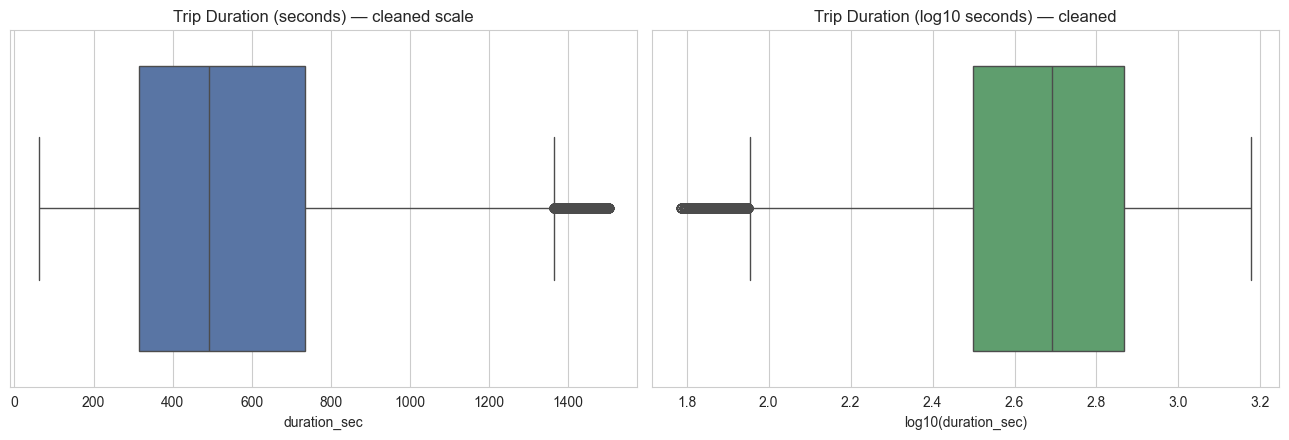

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.boxplot(x=df['duration_sec'], ax=axes[0], color='#4C72B0')
axes[0].set_title('Trip Duration (seconds) — cleaned scale')
axes[0].set_xlabel('duration_sec')

sns.boxplot(x=np.log10(df['duration_sec']), ax=axes[1], color='#55A868')
axes[1].set_title('Trip Duration (log10 seconds) — cleaned')
axes[1].set_xlabel('log10(duration_sec)')

plt.tight_layout()
plt.show()


In [24]:
for col in ['user_type', 'member_gender', 'bike_share_for_all_trip']:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False))
    print()

--- user_type ---
user_type
Subscriber    157095
Customer       16186
Name: count, dtype: int64

--- member_gender ---
member_gender
Male       124398
Female      38255
Unknown      7305
Other        3323
Name: count, dtype: int64

--- bike_share_for_all_trip ---
bike_share_for_all_trip
No     157209
Yes     16072
Name: count, dtype: int64



## 5. Feature Engineering

### Trip Duration in Minutes

In [25]:
df['trip_duration_minutes'] = df['duration_sec'] / 60

print(df[['duration_sec', 'trip_duration_minutes']].head())
print()
print(df['trip_duration_minutes'].describe())


   duration_sec  trip_duration_minutes
0          1147              19.116667
1          1049              17.483333
2           458               7.633333
3           506               8.433333
4          1176              19.600000

count    173281.000000
mean          9.229159
std           5.111585
min           1.016667
25%           5.266667
50%           8.183333
75%          12.250000
max          25.033333
Name: trip_duration_minutes, dtype: float64


### Age

In [26]:
# Use the actual year represented by the cleaned trip timestamps.
REFERENCE_YEAR = int(df['start_time'].dt.year.max())
print('Reference year used:', REFERENCE_YEAR)

df['age'] = REFERENCE_YEAR - df['member_birth_year']

# Remove impossible ages created by invalid birth years.
invalid_age_mask = (df['age'] < 0) | (df['age'] > 100)
df.loc[invalid_age_mask, ['member_birth_year', 'age']] = np.nan

print('Invalid ages removed from demographic fields:', invalid_age_mask.sum())
print(df[['member_birth_year', 'age']].describe())


Reference year used: 2019
Invalid ages removed from demographic fields: 0
       member_birth_year            age
count      165909.000000  165909.000000
mean         1984.870387      34.129613
std             9.897415       9.897415
min          1920.000000      18.000000
25%          1980.000000      27.000000
50%          1987.000000      32.000000
75%          1992.000000      39.000000
max          2001.000000      99.000000


In [27]:
def age_group(age):
    if pd.isna(age):
        return 'Unknown'
    elif age <= 24:
        return 'Young'
    elif age <= 59:
        return 'Adult'
    else:
        return 'Senior'

df['age_group'] = df['age'].apply(age_group)

# Time fields used directly by the interactive dashboard.
df['trip_date'] = df['start_time'].dt.normalize()
df['day_of_week'] = df['start_time'].dt.day_name()
df['week_start'] = df['start_time'].dt.to_period('W').apply(lambda p: p.start_time)
df['month'] = df['start_time'].dt.to_period('M').astype(str)
df['start_hour'] = df['start_time'].dt.hour

print(df['age_group'].value_counts(dropna=False))
print()
print(df[['trip_date', 'day_of_week', 'week_start', 'month', 'start_hour']].head())


age_group
Adult      140664
Young       21491
Unknown      7372
Senior       3754
Name: count, dtype: int64

   trip_date day_of_week week_start    month  start_hour
0 2019-02-28    Thursday 2019-02-25  2019-02          23
1 2019-02-28    Thursday 2019-02-25  2019-02          23
2 2019-02-28    Thursday 2019-02-25  2019-02          23
3 2019-02-28    Thursday 2019-02-25  2019-02          23
4 2019-02-28    Thursday 2019-02-25  2019-02          23


## 6. Encoding & Scaling

In [28]:
categorical_cols = ['user_type', 'member_gender', 'bike_share_for_all_trip', 'age_group']

for col in categorical_cols:
    print(f'{col}: {df[col].nunique(dropna=True)} unique values -> {sorted(df[col].dropna().unique().tolist())}')


user_type: 2 unique values -> ['Customer', 'Subscriber']
member_gender: 4 unique values -> ['Female', 'Male', 'Other', 'Unknown']
bike_share_for_all_trip: 2 unique values -> ['No', 'Yes']
age_group: 4 unique values -> ['Adult', 'Senior', 'Unknown', 'Young']


In [29]:
df_encoded = pd.get_dummies(df, columns=categorical_cols, prefix=categorical_cols, dummy_na=False)

print("Original df shape:   ", df.shape)
print("df_encoded shape:    ", df_encoded.shape)
print()
print("New encoded columns created:")
print([c for c in df_encoded.columns if c not in df.columns])

Original df shape:    (173281, 24)
df_encoded shape:     (173281, 32)

New encoded columns created:
['user_type_Customer', 'user_type_Subscriber', 'member_gender_Female', 'member_gender_Male', 'member_gender_Other', 'member_gender_Unknown', 'bike_share_for_all_trip_No', 'bike_share_for_all_trip_Yes', 'age_group_Adult', 'age_group_Senior', 'age_group_Unknown', 'age_group_Young']


## 7. Univariate Analysis

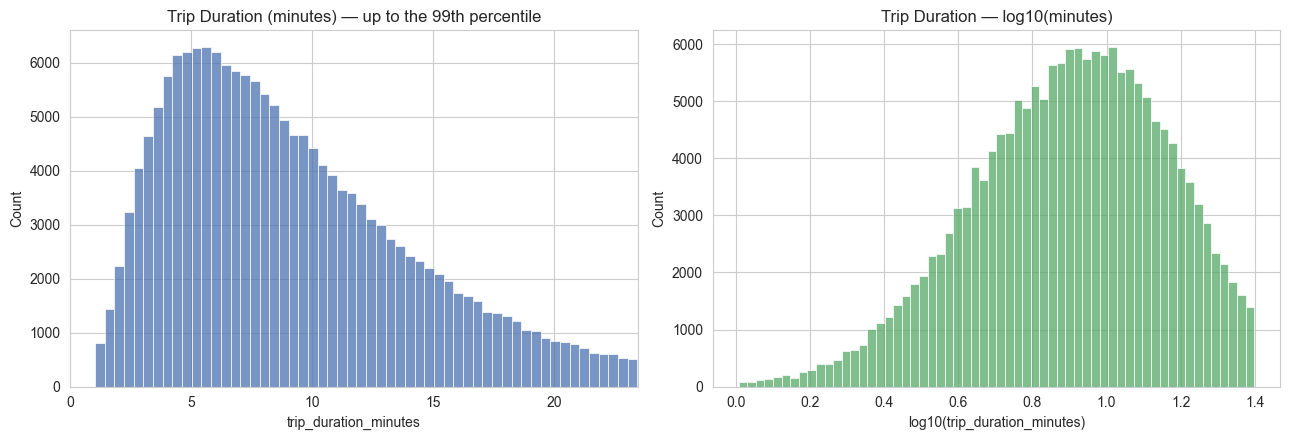

count    173281.000000
mean          9.229159
std           5.111585
min           1.016667
25%           5.266667
50%           8.183333
75%          12.250000
max          25.033333
Name: trip_duration_minutes, dtype: float64


In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(df['trip_duration_minutes'], bins=60, ax=axes[0], color='#4C72B0')
axes[0].set_xlim(0, df['trip_duration_minutes'].quantile(0.99))
axes[0].set_title('Trip Duration (minutes) — up to the 99th percentile')
axes[0].set_xlabel('trip_duration_minutes')

sns.histplot(np.log10(df['trip_duration_minutes']), bins=60, ax=axes[1], color='#55A868')
axes[1].set_title('Trip Duration — log10(minutes)')
axes[1].set_xlabel('log10(trip_duration_minutes)')

plt.tight_layout()
plt.show()

print(df['trip_duration_minutes'].describe())


C:\Users\New Star Computer 25\AppData\Local\Temp\ipykernel_7320\1961118940.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='user_type', order=order, palette=['#4C72B0', '#DD8452'])


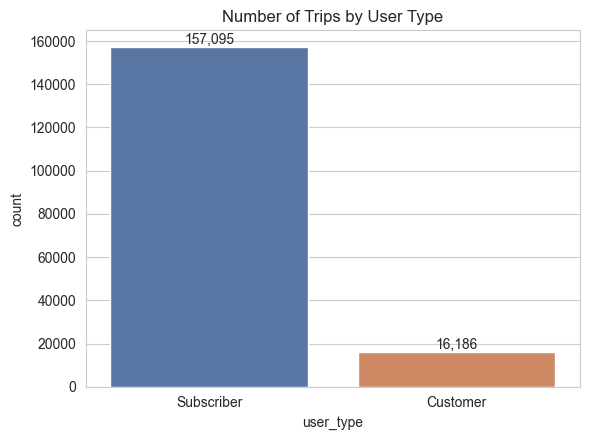

user_type
Subscriber    157095
Customer       16186
Name: count, dtype: int64
user_type
Subscriber    90.66
Customer       9.34
Name: proportion, dtype: float64


In [31]:
plt.figure(figsize=(6, 4.5))
order = df['user_type'].value_counts().index
ax = sns.countplot(data=df, x='user_type', order=order, palette=['#4C72B0', '#DD8452'])
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom')
plt.title('Number of Trips by User Type')
plt.tight_layout()
plt.show()

print(df['user_type'].value_counts())
print((df['user_type'].value_counts(normalize=True) * 100).round(2))

C:\Users\New Star Computer 25\AppData\Local\Temp\ipykernel_7320\4002982782.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=gender_counts.index, y=gender_counts.values, palette=['#4C72B0', '#DD8452', '#55A868'])
C:\Users\New Star Computer 25\AppData\Local\Temp\ipykernel_7320\4002982782.py:3: UserWarning: 
The palette list has fewer values (3) than needed (4) and will cycle, which may produce an uninterpretable plot.
  ax = sns.barplot(x=gender_counts.index, y=gender_counts.values, palette=['#4C72B0', '#DD8452', '#55A868'])


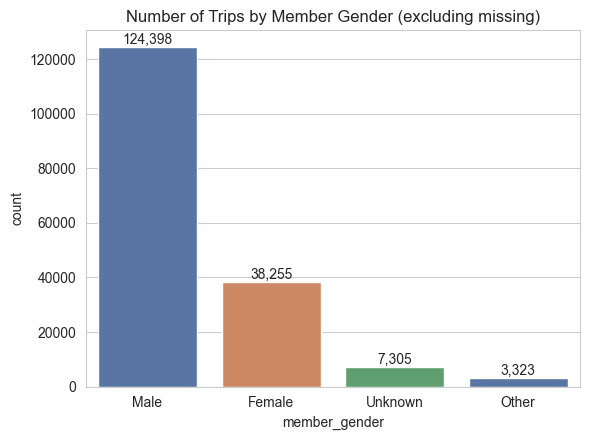

member_gender
Male       124398
Female      38255
Unknown      7305
Other        3323
Name: count, dtype: int64
member_gender
Male       71.79
Female     22.08
Unknown     4.22
Other       1.92
Name: proportion, dtype: float64


In [32]:
plt.figure(figsize=(6, 4.5))
gender_counts = df['member_gender'].value_counts()
ax = sns.barplot(x=gender_counts.index, y=gender_counts.values, palette=['#4C72B0', '#DD8452', '#55A868'])
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom')
plt.title('Number of Trips by Member Gender (excluding missing)')
plt.ylabel('count')
plt.tight_layout()
plt.show()

print(df['member_gender'].value_counts(dropna=False))
print((df['member_gender'].value_counts(normalize=True) * 100).round(2))

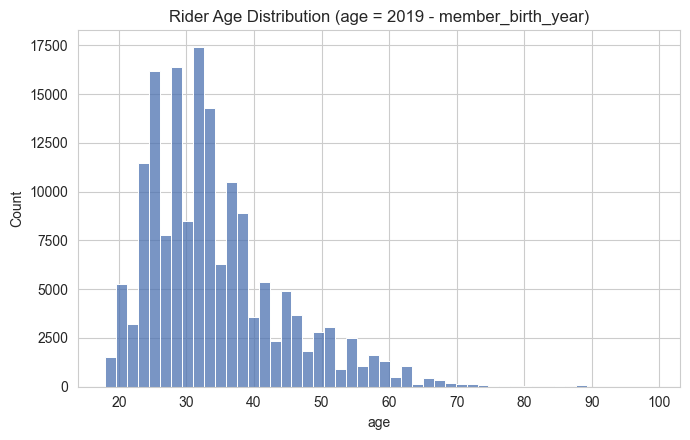

count    165909.000000
mean         34.129613
std           9.897415
min          18.000000
25%          27.000000
50%          32.000000
75%          39.000000
max          99.000000
Name: age, dtype: float64


In [33]:
plt.figure(figsize=(7, 4.5))
sns.histplot(df['age'].dropna(), bins=50, color='#4C72B0')
plt.title('Rider Age Distribution (age = {ref_year} - member_birth_year)'.replace('{ref_year}', str(REFERENCE_YEAR)))
plt.xlabel('age')
plt.tight_layout()
plt.show()

print(df['age'].describe())


C:\Users\New Star Computer 25\AppData\Local\Temp\ipykernel_7320\2857331370.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=bs_counts.index, y=bs_counts.values, palette=['#4C72B0', '#DD8452'])


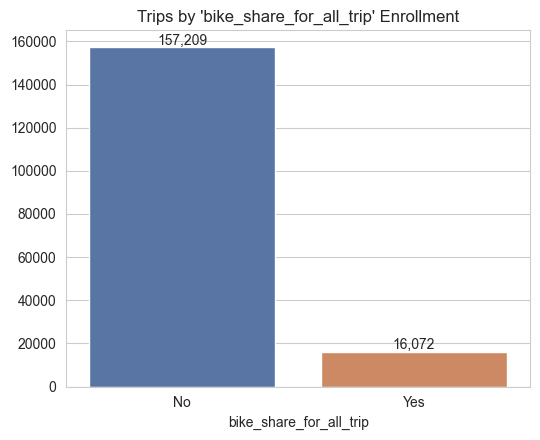

bike_share_for_all_trip
No     157209
Yes     16072
Name: count, dtype: int64
bike_share_for_all_trip
No     90.72
Yes     9.28
Name: proportion, dtype: float64


In [34]:
plt.figure(figsize=(5.5, 4.5))
bs_counts = df['bike_share_for_all_trip'].value_counts()
ax = sns.barplot(x=bs_counts.index, y=bs_counts.values, palette=['#4C72B0', '#DD8452'])
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom')
plt.title("Trips by 'bike_share_for_all_trip' Enrollment")
plt.tight_layout()
plt.show()

print(df['bike_share_for_all_trip'].value_counts())
print((df['bike_share_for_all_trip'].value_counts(normalize=True) * 100).round(2))

## 8. Bivariate Analysis

C:\Users\New Star Computer 25\AppData\Local\Temp\ipykernel_7320\4283013332.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='user_type', y='trip_duration_minutes', showfliers=False, palette=['#4C72B0', '#DD8452'])


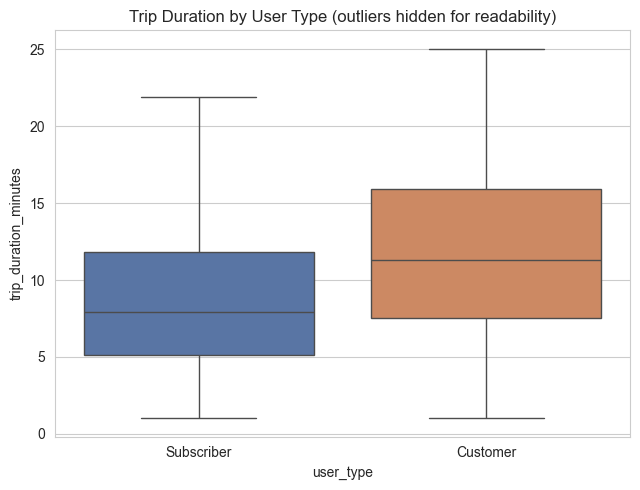

user_type
Customer      11.300000
Subscriber     7.916667
Name: trip_duration_minutes, dtype: float64

user_type
Customer      11.997522
Subscriber     8.943925
Name: trip_duration_minutes, dtype: float64


In [35]:
plt.figure(figsize=(6.5, 5))
sns.boxplot(data=df, x='user_type', y='trip_duration_minutes', showfliers=False, palette=['#4C72B0', '#DD8452'])
plt.title('Trip Duration by User Type (outliers hidden for readability)')
plt.ylabel('trip_duration_minutes')
plt.tight_layout()
plt.show()

print(df.groupby('user_type')['trip_duration_minutes'].median())
print()
print(df.groupby('user_type')['trip_duration_minutes'].mean())

C:\Users\New Star Computer 25\AppData\Local\Temp\ipykernel_7320\1728929407.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='member_gender', y='trip_duration_minutes', showfliers=False,


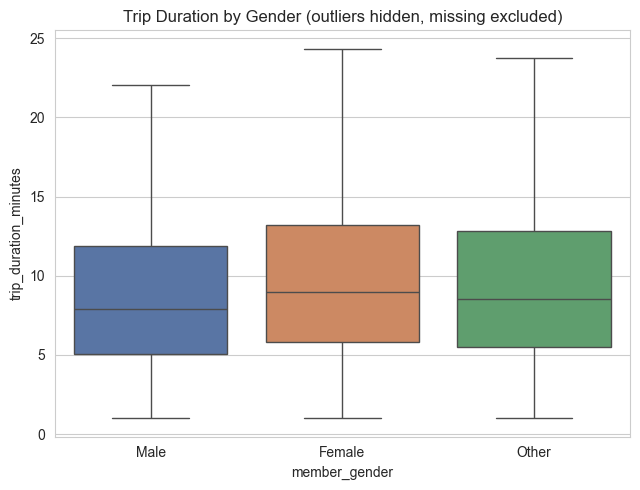

member_gender
Female     8.950000
Male       7.900000
Other      8.550000
Unknown    9.216667
Name: trip_duration_minutes, dtype: float64


In [36]:
plt.figure(figsize=(6.5, 5))
sns.boxplot(data=df, x='member_gender', y='trip_duration_minutes', showfliers=False,
            order=['Male', 'Female', 'Other'], palette=['#4C72B0', '#DD8452', '#55A868'])
plt.title('Trip Duration by Gender (outliers hidden, missing excluded)')
plt.tight_layout()
plt.show()

print(df.groupby('member_gender')['trip_duration_minutes'].median())


C:\Users\New Star Computer 25\AppData\Local\Temp\ipykernel_7320\1411933470.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='age_group', y='trip_duration_minutes', showfliers=False,


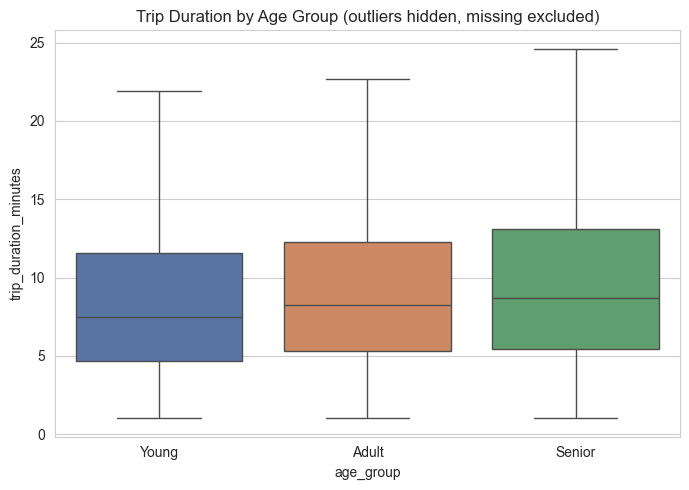

age_group
Adult      8.233333
Senior     8.683333
Unknown    9.183333
Young      7.466667
Name: trip_duration_minutes, dtype: float64

age_group
Adult      140664
Young       21491
Unknown      7372
Senior       3754
Name: count, dtype: int64


In [37]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x='age_group', y='trip_duration_minutes', showfliers=False,
            order=['Young', 'Adult', 'Senior'], palette=['#4C72B0', '#DD8452', '#55A868'])
plt.title('Trip Duration by Age Group (outliers hidden, missing excluded)')
plt.tight_layout()
plt.show()

print(df.groupby('age_group', observed=True)['trip_duration_minutes'].median())
print()
print(df['age_group'].value_counts(dropna=False))


bike_share_for_all_trip      No    Yes
user_type                             
Customer                  16186      0
Subscriber               141023  16072



bike_share_for_all_trip      No    Yes
user_type                             
Customer                 100.00   0.00
Subscriber                89.77  10.23


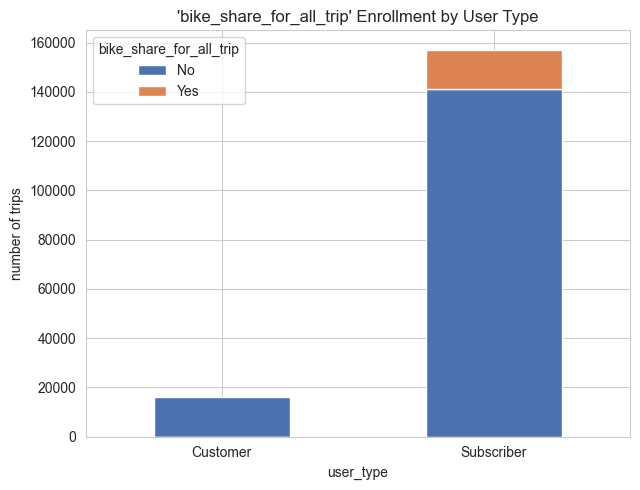

In [38]:
ct = pd.crosstab(df['user_type'], df['bike_share_for_all_trip'])
print(ct)
print()
ct_pct = pd.crosstab(df['user_type'], df['bike_share_for_all_trip'], normalize='index') * 100
print(ct_pct.round(2))

ct.plot(kind='bar', stacked=True, figsize=(6.5, 5), color=['#4C72B0', '#DD8452'])
plt.title("'bike_share_for_all_trip' Enrollment by User Type")
plt.ylabel('number of trips')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

C:\Users\New Star Computer 25\AppData\Local\Temp\ipykernel_7320\3973019004.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=top_stations.index, x=top_stations.values, palette='Blues_r')


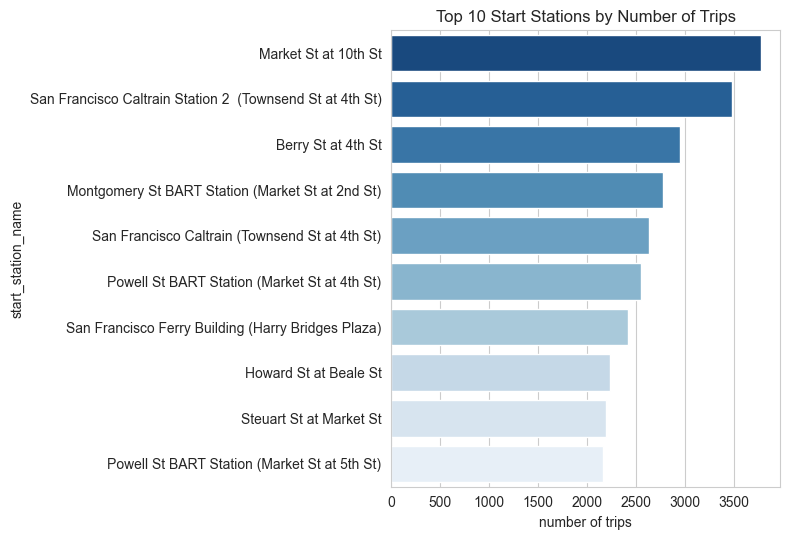

start_station_name
Market St at 10th St                                         3786
San Francisco Caltrain Station 2  (Townsend St at 4th St)    3480
Berry St at 4th St                                           2953
Montgomery St BART Station (Market St at 2nd St)             2775
San Francisco Caltrain (Townsend St at 4th St)               2637
Powell St BART Station (Market St at 4th St)                 2553
San Francisco Ferry Building (Harry Bridges Plaza)           2421
Howard St at Beale St                                        2240
Steuart St at Market St                                      2200
Powell St BART Station (Market St at 5th St)                 2163
Name: count, dtype: int64

                                                   route  trips
5609   Berry St at 4th St → San Francisco Ferry Build...    334
10539  Grand Ave at Perkins St → 19th Street BART Sta...    309
19926  The Embarcadero at Sansome St → Steuart St at ...    282
1693   19th Street BART Station → Gran

In [39]:
top_stations = df['start_station_name'].value_counts().head(10)

plt.figure(figsize=(8, 5.5))
sns.barplot(y=top_stations.index, x=top_stations.values, palette='Blues_r')
plt.title('Top 10 Start Stations by Number of Trips')
plt.xlabel('number of trips')
plt.tight_layout()
plt.show()

print(top_stations)

# Top station-to-station routes.
route_counts = (
    df.groupby(['start_station_name', 'end_station_name'])
      .size()
      .reset_index(name='trips')
      .sort_values('trips', ascending=False)
      .head(10)
)
route_counts['route'] = route_counts['start_station_name'] + ' → ' + route_counts['end_station_name']
print()
print(route_counts[['route', 'trips']])


## 9. Multivariate Analysis

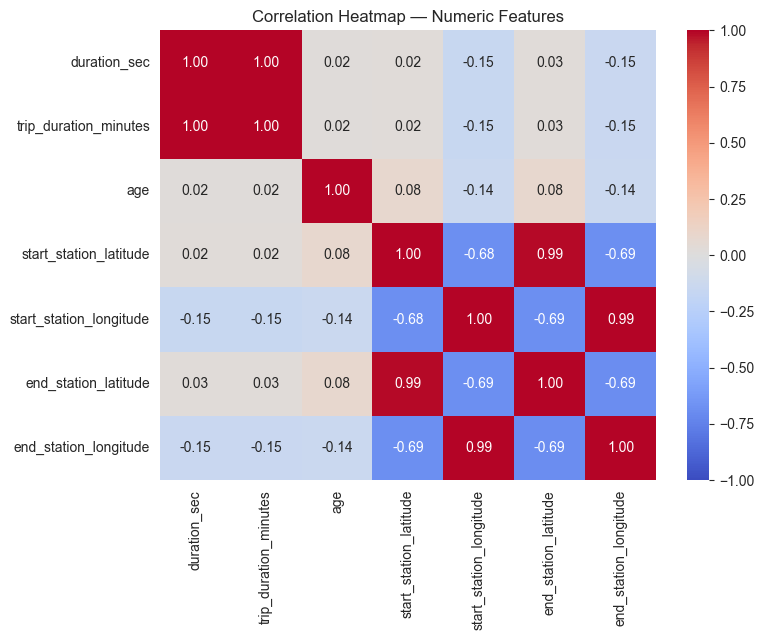

,duration_sec,trip_duration_minutes,age,start_station_latitude,start_station_longitude,end_station_latitude,end_station_longitude
duration_sec,1.000000,1.000000,0.023245,0.024158,-0.149186,0.026518,-0.147346
trip_duration_minutes,1.000000,1.000000,0.023245,0.024158,-0.149186,0.026518,-0.147346
age,0.023245,0.023245,1.000000,0.080827,-0.137233,0.080938,-0.138105
start_station_latitude,0.024158,0.024158,0.080827,1.000000,-0.681308,0.991104,-0.686864
start_station_longitude,-0.149186,-0.149186,-0.137233,-0.681308,1.000000,-0.685697,0.992948
end_station_latitude,0.026518,0.026518,0.080938,0.991104,-0.685697,1.000000,-0.688421
end_station_longitude,-0.147346,-0.147346,-0.138105,-0.686864,0.992948,-0.688421,1.000000


In [40]:
numeric_cols = ['duration_sec', 'trip_duration_minutes', 'age',
                'start_station_latitude', 'start_station_longitude',
                'end_station_latitude', 'end_station_longitude']

corr = df[numeric_cols].corr()

plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlation Heatmap — Numeric Features')
plt.tight_layout()
plt.show()

corr

member_gender  Female   Male  Other  Unknown
user_type                                   
Customer        12.18  10.90  10.71    11.35
Subscriber       8.67   7.68   8.28     8.20


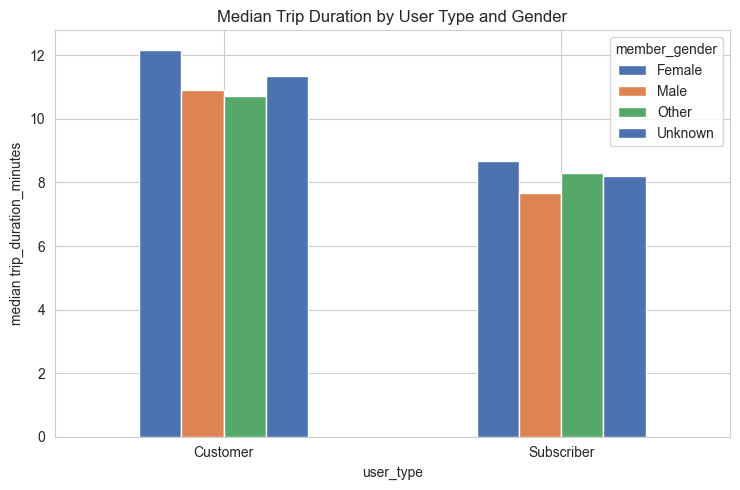

In [41]:
pivot = df.pivot_table(values='trip_duration_minutes', index='user_type', columns='member_gender',
                        aggfunc='median', observed=True)
print(pivot.round(2))

pivot.plot(kind='bar', figsize=(7.5, 5), color=['#4C72B0', '#DD8452', '#55A868'])
plt.title('Median Trip Duration by User Type and Gender')
plt.ylabel('median trip_duration_minutes')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

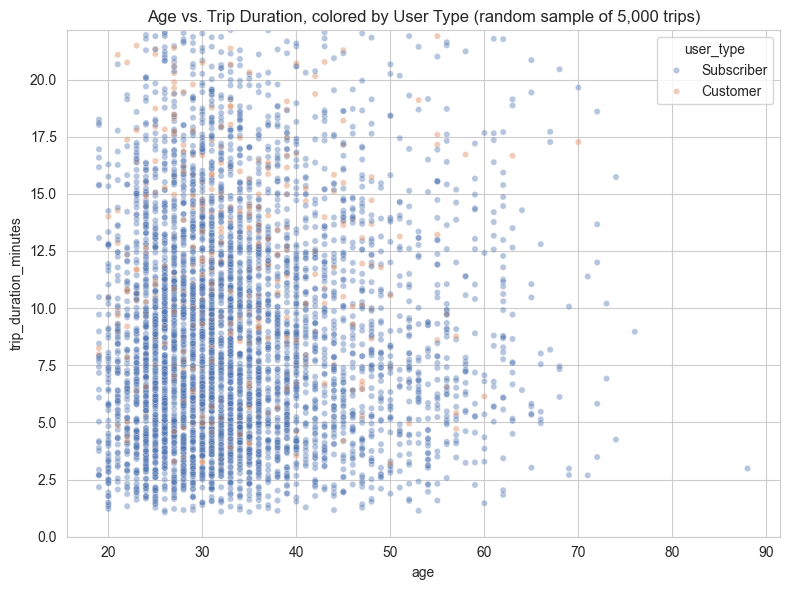

In [42]:
sample = df.dropna(subset=['age', 'trip_duration_minutes']).sample(
    n=min(5000, df.dropna(subset=['age', 'trip_duration_minutes']).shape[0]), random_state=42)

plt.figure(figsize=(8, 6))
sns.scatterplot(data=sample, x='age', y='trip_duration_minutes', hue='user_type',
                alpha=0.4, s=20, palette=['#4C72B0', '#DD8452'])
plt.ylim(0, sample['trip_duration_minutes'].quantile(0.98))
plt.title('Age vs. Trip Duration, colored by User Type (random sample of 5,000 trips)')
plt.tight_layout()
plt.show()


## 11. Final Clean Dataset

In [43]:
print('=== FINAL CLEAN DATASET ===')
print('Original (df_raw):', df_raw.shape)
print('Cleaned  (df):     ', df.shape)
print('Rows removed:', df_raw.shape[0] - df.shape[0])
print('Columns added:', df.shape[1] - df_raw.shape[1])
print('Added columns:', [c for c in df.columns if c not in df_raw.columns])


=== FINAL CLEAN DATASET ===
Original (df_raw): (183412, 16)
Cleaned  (df):      (173281, 24)
Rows removed: 10131
Columns added: 8
Added columns: ['trip_duration_minutes', 'age', 'age_group', 'trip_date', 'day_of_week', 'week_start', 'month', 'start_hour']


In [44]:
print('=== MISSING VALUES AFTER TREATMENT ===')
missing_after = df.isna().sum().sort_values(ascending=False)
print(missing_after[missing_after > 0])

print()
print('Dashboard-critical columns check:')
required_for_dashboard = [
    'start_time', 'end_time', 'user_type', 'member_gender',
    'age_group', 'trip_duration_minutes',
    'start_station_name', 'end_station_name'
]
print(df[required_for_dashboard].isna().sum())


=== MISSING VALUES AFTER TREATMENT ===
age                  7372
member_birth_year    7372
dtype: int64

Dashboard-critical columns check:
start_time               0
end_time                 0
user_type                0
member_gender            0
age_group                0
trip_duration_minutes    0
start_station_name       0
end_station_name         0
dtype: int64


In [45]:
print('Duplicate rows remaining:', df.duplicated().sum())
print('Invalid start_time values:', df['start_time'].isna().sum())
print('Invalid end_time values:', df['end_time'].isna().sum())
print()
df.info()


Duplicate rows remaining: 0
Invalid start_time values: 0
Invalid end_time values: 0

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 173281 entries, 0 to 173280
Data columns (total 24 columns):
 #   Column                   Non-Null Count   Dtype         
---  ------                   --------------   -----         
 0   duration_sec             173281 non-null  int64         
 1   start_time               173281 non-null  datetime64[ns]
 2   end_time                 173281 non-null  datetime64[ns]
 3   start_station_id         173281 non-null  float64       
 4   start_station_name       173281 non-null  object        
 5   start_station_latitude   173281 non-null  float64       
 6   start_station_longitude  173281 non-null  float64       
 7   end_station_id           173281 non-null  float64       
 8   end_station_name         173281 non-null  object        
 9   end_station_latitude     173281 non-null  float64       
 10  end_station_longitude    173281 non-null  float64      

In [46]:
print('Engineered features present:')
for c in ['trip_duration_minutes', 'age', 'age_group', 'trip_date', 'day_of_week', 'week_start', 'month', 'start_hour']:
    print(f' - {c}: dtype={df[c].dtype}, missing={df[c].isna().sum()}')

print()
df.head()


Engineered features present:
 - trip_duration_minutes: dtype=float64, missing=0
 - age: dtype=float64, missing=7372
 - age_group: dtype=object, missing=0
 - trip_date: dtype=datetime64[ns], missing=0
 - day_of_week: dtype=object, missing=0
 - week_start: dtype=datetime64[ns], missing=0
 - month: dtype=object, missing=0
 - start_hour: dtype=int32, missing=0



,duration_sec,start_time,end_time,start_station_id,start_station_name,start_station_latitude,start_station_longitude,end_station_id,end_station_name,end_station_latitude,end_station_longitude,bike_id,user_type,member_birth_year,member_gender,bike_share_for_all_trip,trip_duration_minutes,age,age_group,trip_date,day_of_week,week_start,month,start_hour
0,1147,2019-02-28 23:55:35.104,2019-03-01 00:14:42.588,300.0,Palm St at Willow St,37.317298,-121.884995,312.0,San Jose Diridon Station,37.329732,-121.901782,3803,Subscriber,1983.0,Female,No,19.116667,36.0,Adult,2019-02-28,Thursday,2019-02-25,2019-02,23
1,1049,2019-02-28 23:49:47.699,2019-03-01 00:07:17.025,19.0,Post St at Kearny St,37.788975,-122.403452,121.0,Mission Playground,37.759210,-122.421339,6488,Subscriber,1992.0,Male,No,17.483333,27.0,Adult,2019-02-28,Thursday,2019-02-25,2019-02,23
2,458,2019-02-28 23:57:57.211,2019-03-01 00:05:35.435,370.0,Jones St at Post St,37.787327,-122.413278,43.0,San Francisco Public Library (Grove St at Hyde...,37.778768,-122.415929,5318,Subscriber,1996.0,Female,Yes,7.633333,23.0,Young,2019-02-28,Thursday,2019-02-25,2019-02,23
3,506,2019-02-28 23:56:55.540,2019-03-01 00:05:21.733,44.0,Civic Center/UN Plaza BART Station (Market St ...,37.781074,-122.411738,343.0,Bryant St at 2nd St,37.783172,-122.393572,5848,Subscriber,1993.0,Male,No,8.433333,26.0,Adult,2019-02-28,Thursday,2019-02-25,2019-02,23
4,1176,2019-02-28 23:45:12.651,2019-03-01 00:04:49.184,127.0,Valencia St at 21st St,37.756708,-122.421025,323.0,Broadway at Kearny,37.798014,-122.405950,5328,Customer,1990.0,Male,No,19.600000,29.0,Adult,2019-02-28,Thursday,2019-02-25,2019-02,23


In [47]:
OUTPUT_PATH = 'fordgobike_201902_cleaned.csv'
df.to_csv(OUTPUT_PATH, index=False)
print(f'Cleaned dataset exported to: {OUTPUT_PATH}')
print('Final shape:', df.shape)
print('Date range:', df['start_time'].min(), 'to', df['start_time'].max())


Cleaned dataset exported to: fordgobike_201902_cleaned.csv
Final shape: (173281, 24)
Date range: 2019-02-01 00:00:20.636000 to 2019-02-28 23:59:18.548000


In [48]:
import sys
print(sys.executable)

c:\Program Files\Python313\python.exe
